# Batch NPV over an ensemble of cases

Each `caseN_energy_water.csv` is paired with row `N` of the case-definition table,
which carries that case's `layout_id`, well cells (`INJn_I/J`, `PROn_I/J`),
`param_id` and the geological / geomechanical parameters. Output is one row per
case: every case-definition column plus the economics and the NPV.

$$\mathrm{NPV} = -\mathrm{CAPEX_{wells}} - \mathrm{CAPEX_{facilities}}
+ \sum_{t=1}^{T}\frac{1}{(1+\gamma)^t}\left(\mathrm{REVENUE_{energy}}(t) - \mathrm{OPEX}(t)\right)$$

## Conventions

| Item | Convention |
|---|---|
| `i`, `j`, `k` | 1-based inclusive (CMG style) |
| Reservoir | layers 5–20 (1-based) → python `k = 4..19` |
| Well path | ① 1 km vertical lead → ② deviated straight line to reservoir top at the well's (i, j) → ③ vertical to the base of layer 20 |
| Surface | one shared facility, placed by grid index |
| Flowline | Σ over wells of the map-view distance facility → well |
| CAPEX | undiscounted at t = 0; wells = drilling, facilities = fixed cost + flowline |
| Revenue | energy price × *net* thermal energy (produced − injected) |
| Water handling | charged on *produced* volume |

Profiles are cumulative and get differenced to annual increments, so a 31-row
file starting at the t = 0 baseline gives 30 years.

`NPV_END_DATE` fixes the cut-off so every case is valued over the same period.
A case whose profile stops short of that date gets no NPV rather than one
computed over fewer years, which would not be comparable. Set it to `None` to
value each case out to its own last period.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from calculate_npv import (
    EconParams, load_grid, load_case_table, evaluate_folder,
    active_mask, ij_to_xy, wells_from_row,
)

MM = 1e6

# ---- paths -----------------------------------------------------------------
GRID_PATH  = "data_other/JD_geothermal_coor&fault.npy"
CASES_CSV  = "sim_sampling/gen_000_cases_seed11.csv"
FOLDER     = "sim_gen_000/0_energy_water_csv"          # holds caseN_energy_water.csv
OUT_CSV    = "sim_gen_000/0_npv_summary.csv"

# ---- configuration ---------------------------------------------------------
FACILITY_IJ  = (73, 96)                  # shared pad, grid index
K_TOP, K_BOT = 5, 20                     # reservoir layers, 1-based inclusive
NPV_END_DATE = "2060-01-01"              # evaluate every case to this date;
                                         # None uses each profile's own end
ENERGY_BASIS = "net"                     # "net" or "produced"
WATER_BASIS  = "produced"                # "produced" / "injected" / "both" / "max"

params = EconParams()                    # defaults = the project parameter table

grid = load_grid(GRID_PATH)
cases = load_case_table(CASES_CSV)

print(f"grid  : {grid.shape[0]} x {grid.shape[1]} x {grid.shape[2]}")
print(f"cases : {len(cases)} rows, {cases['layout_id'].nunique()} layout(s), "
      f"{cases['param_id'].nunique()} parameter set(s)")
cases.head(3)

grid  : 139 x 248 x 23
cases : 200 rows, 20 layout(s), 10 parameter set(s)


,case,layout_id,INJ1_I,INJ1_J,INJ2_I,INJ2_J,INJ3_I,INJ3_J,PRO1_I,PRO1_J,...,beta,cos_2beta,sin_2beta,sigma_x_grad,sigma_y_grad,tau_xy_grad,sigma_x_ref,sigma_y_ref,sigma_z_ref,tau_xy_ref
0,1,1,50,110,54,97,63,109,50,80,...,78.6743,-0.922865,0.385123,-5.81606,-8.45029,0.549650,13811.2,20066.7,30651.9,-1305.240
1,2,1,50,110,54,97,63,109,50,80,...,86.8168,-0.993833,0.110886,-5.77743,-8.97853,0.178580,13719.5,21321.1,29420.6,-424.068
2,3,1,50,110,54,97,63,109,50,80,...,84.1971,-0.979555,0.201176,-5.69761,-8.57598,0.295572,13529.9,20365.1,29968.1,-701.887


## Run the batch

In [3]:
summary = evaluate_folder(
    grid, FOLDER,
    case_table=cases,                    # per-case wells + all its columns
    params=params,
    facility_ij=FACILITY_IJ,
    energy_basis=ENERGY_BASIS, water_basis=WATER_BASIS,
    npv_end_date=NPV_END_DATE,
    k_top=K_TOP, k_bot=K_BOT,
    out_csv=OUT_CSV,
    keep_all_cases=True,                 # every case row is written; economics
)                                        # are left empty where there is no NPV

evaluated = summary.dropna(subset=["npv_usd"])

print(f"{summary.shape[0]} case rows x {summary.shape[1]} columns written to "
      f"{OUT_CSV}")
print(f"{len(evaluated)} with an NPV to {NPV_END_DATE}, "
      f"{len(summary) - len(evaluated)} left empty")
if len(evaluated):
    print(f"periods used : {sorted(evaluated['n_years'].unique())}")

evaluated[["case", "layout_id", "param_id", "injectors", "producers",
         "total_well_length_m", "net_energy_PJ", "water_m3",
         "revenue_pv_usd", "capex_total_usd", "opex_pv_usd", "npv_usd"]]

found 193 case file(s) in sim_gen_000/0_energy_water_csv


D:\Users\jihuid\AppData\Local\Temp\10\ipykernel_55192\3062680902.py:1: UserWarning: case49: skipped (ValueError: no period ends on or before npv_end_date 2060-01-01)
  summary = evaluate_folder(
D:\Users\jihuid\AppData\Local\Temp\10\ipykernel_55192\3062680902.py:1: UserWarning: case65: skipped (ValueError: no period ends on or before npv_end_date 2060-01-01)
  summary = evaluate_folder(
D:\Users\jihuid\AppData\Local\Temp\10\ipykernel_55192\3062680902.py:1: UserWarning: case81: skipped (ValueError: no period ends on or before npv_end_date 2060-01-01)
  summary = evaluate_folder(


written: sim_gen_000/0_npv_summary.csv  (200 rows, 190 with an NPV)
skipped 3: ['case49', 'case65', 'case81']
200 case rows x 65 columns written to sim_gen_000/0_npv_summary.csv
190 with an NPV to 2060-01-01, 10 left empty
periods used : [30.0]


,case,layout_id,param_id,injectors,producers,total_well_length_m,net_energy_PJ,water_m3,revenue_pv_usd,capex_total_usd,opex_pv_usd,npv_usd
0,1,1,1,50-110;54-97;63-109,50-80;70-80;65-92,19052.011382,102.622219,328569811.4,4.867321e+08,2.020127e+08,1.398204e+08,1.448991e+08
1,2,1,2,50-110;54-97;63-109,50-80;70-80;65-92,19052.011382,80.038030,248795148.5,3.796057e+08,2.020127e+08,1.327859e+08,4.480714e+07
2,3,1,3,50-110;54-97;63-109,50-80;70-80;65-92,19052.011382,104.631891,328589700.0,4.926534e+08,2.020127e+08,1.398193e+08,1.508214e+08
3,4,1,4,50-110;54-97;63-109,50-80;70-80;65-92,19052.011382,8.054418,24840401.3,3.976378e+07,2.020127e+08,1.119211e+08,-2.741700e+08
4,5,1,5,50-110;54-97;63-109,50-80;70-80;65-92,19052.011382,104.029710,328543986.8,4.881312e+08,2.020127e+08,1.398190e+08,1.462996e+08
...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,20,6,46-97;66-100;70-79,54-86;62-118;66-113,18748.071158,18.004192,61700993.2,8.726846e+07,2.012751e+08,1.154162e+08,-2.294228e+08
196,197,20,7,46-97;66-100;70-79,54-86;62-118;66-113,18748.071158,16.555045,56169439.9,7.994616e+07,2.012751e+08,1.148633e+08,-2.361923e+08
197,198,20,8,46-97;66-100;70-79,54-86;62-118;66-113,18748.071158,51.085850,174672556.1,2.450965e+08,2.012751e+08,1.260694e+08,-8.224802e+07
198,199,20,9,46-97;66-100;70-79,54-86;62-118;66-113,18748.071158,94.625355,328621493.6,4.430932e+08,2.012751e+08,1.398244e+08,1.019937e+08


Only cases with a profile file in `FOLDER` are evaluated; the rest of the
table is ignored. A case whose file is unreadable, or that has no matching row
in the table, is skipped with a warning rather than aborting the batch.

In [4]:
npv_mm = evaluated["npv_usd"] / MM
print(f"NPV (MM$)    : min {npv_mm.min():>8.1f}   median {npv_mm.median():>8.1f}"
      f"   max {npv_mm.max():>8.1f}")
print(f"positive NPV : {(npv_mm > 0).sum()} of {len(evaluated)}")
print(f"best / worst : case {summary.loc[npv_mm.idxmax(), 'case']} / "
      f"case {summary.loc[npv_mm.idxmin(), 'case']}")

# revenue scales linearly with price, so break-even follows from the PV terms
summary["breakeven_usd_per_kwh"] = (
    params.energy_price_usd_per_kwh
    * (summary["capex_total_usd"] + summary["opex_pv_usd"])
    / summary["revenue_pv_usd"]
)
summary.loc[evaluated.index,
            ["case", "npv_usd", "breakeven_usd_per_kwh"]].round(4)

NPV (MM$)    : min   -308.8   median     36.0   max    163.2
positive NPV : 102 of 190
best / worst : case 183 / case 24


,case,npv_usd,breakeven_usd_per_kwh
0,1,1.448991e+08,0.0281
1,2,4.480714e+07,0.0353
2,3,1.508214e+08,0.0278
3,4,-2.741700e+08,0.3158
4,5,1.462996e+08,0.0280
...,...,...,...
195,196,-2.294228e+08,0.1452
196,197,-2.361923e+08,0.1582
197,198,-8.224802e+07,0.0534
198,199,1.019937e+08,0.0308


## Spread across cases

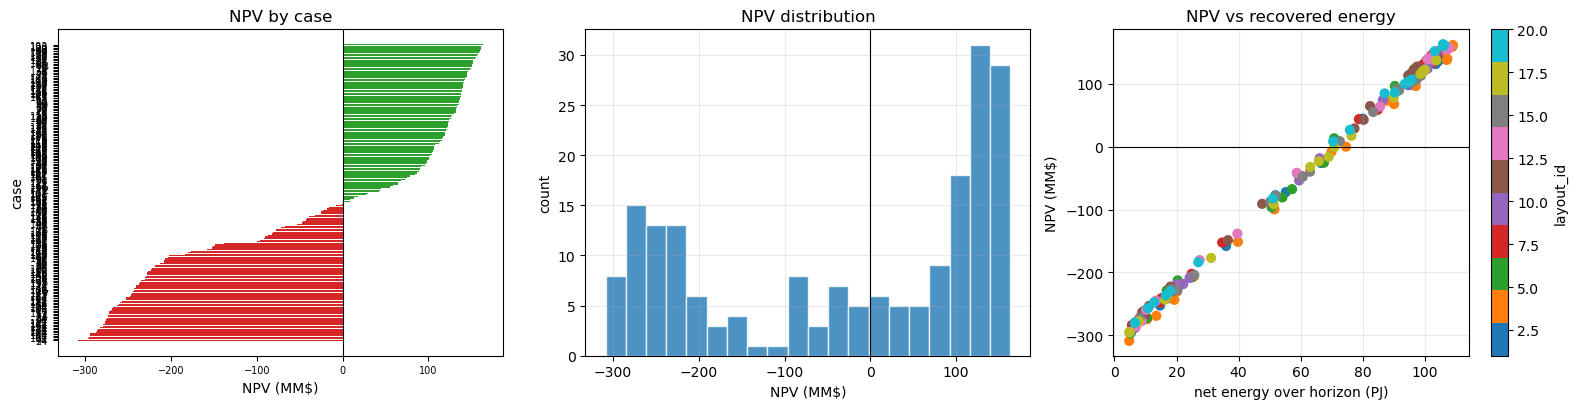

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))

order = evaluated.sort_values("npv_usd")
axs[0].barh(order["case"].astype(str), order["npv_usd"] / MM,
            color=np.where(order["npv_usd"] > 0, "tab:green", "tab:red"))
axs[0].axvline(0, color="k", lw=0.8)
axs[0].set_xlabel("NPV (MM$)"); axs[0].set_ylabel("case")
axs[0].set_title("NPV by case"); axs[0].tick_params(labelsize=7)

axs[1].hist(npv_mm, bins=min(20, max(4, len(evaluated) // 2)),
            color="tab:blue", alpha=0.8, edgecolor="w")
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_xlabel("NPV (MM$)"); axs[1].set_ylabel("count")
axs[1].set_title("NPV distribution")

sc = axs[2].scatter(evaluated["net_energy_PJ"], npv_mm, s=40,
                    c=evaluated["layout_id"], cmap="tab10")
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xlabel("net energy over horizon (PJ)"); axs[2].set_ylabel("NPV (MM$)")
axs[2].set_title("NPV vs recovered energy")
if evaluated["layout_id"].nunique() > 1:
    plt.colorbar(sc, ax=axs[2], label="layout_id")
for ax in axs[1:]:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

With one layout the CAPEX is identical across cases, so the NPV spread is
driven entirely by the parameter set. Across several layouts, splitting by
`layout_id` separates the placement effect from the geological one.

In [6]:
by_layout = evaluated.groupby("layout_id").agg(
    n_cases=("case", "size"),
    well_length_m=("total_well_length_m", "first"),
    capex_MM=("capex_total_usd", lambda s: s.iloc[0] / MM),
    energy_PJ_mean=("net_energy_PJ", "mean"),
    npv_MM_min=("npv_usd", lambda s: s.min() / MM),
    npv_MM_mean=("npv_usd", lambda s: s.mean() / MM),
    npv_MM_max=("npv_usd", lambda s: s.max() / MM),
).round(2)
by_layout

,n_cases,well_length_m,capex_MM,energy_PJ_mean,npv_MM_min,npv_MM_mean,npv_MM_max
layout_id,,,,,,,
1,10,19052.01,202.01,68.92,-274.17,-5.92,150.82
2,10,19989.35,210.49,60.21,-295.10,-54.61,136.53
3,10,21009.79,221.62,60.53,-308.78,-62.95,139.91
4,10,20832.13,214.14,75.44,-274.21,14.31,161.88
5,9,20214.37,211.47,51.81,-296.96,-91.31,121.23
6,10,18754.91,196.14,66.43,-260.62,-10.71,137.41
7,9,19314.80,205.34,66.32,-274.53,-22.19,133.50
8,10,18803.66,199.99,64.83,-283.42,-20.60,151.83
9,8,20061.36,210.11,63.62,-288.05,-37.35,124.22


## Layout check

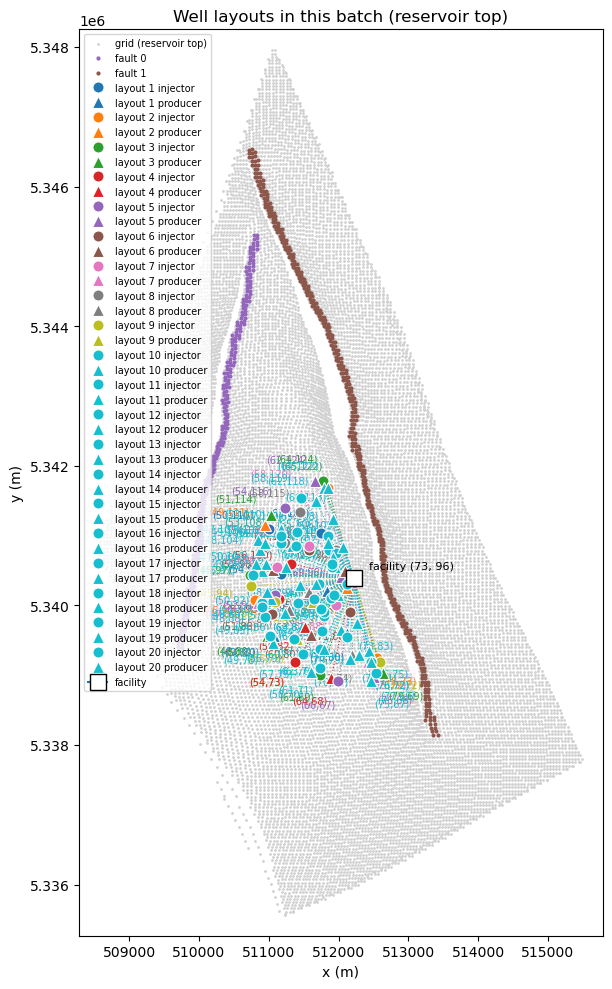

In [7]:
kk = K_TOP - 1
xs, ys = grid[:, :, kk, 0], grid[:, :, kk, 1]
fault = grid[:, :, kk, 3]
act = active_mask(grid)
fx, fy = ij_to_xy(grid, *FACILITY_IJ, k=K_TOP)

fig, ax = plt.subplots(figsize=(6.5, 10))
ax.scatter(xs[act], ys[act], s=1.0, color="0.82", label="grid (reservoir top)")

fault_colors = {0.0: "tab:purple", 1.0: "tab:brown"}
for fid in np.unique(fault[act & ~np.isnan(fault)]):
    m = act & (fault == fid)
    ax.scatter(xs[m], ys[m], s=4, color=fault_colors.get(fid, "0.3"),
               label=f"fault {int(fid)}", zorder=2)

# one marker set per distinct layout present in the batch
seen = evaluated.drop_duplicates("layout_id")
cmap = plt.get_cmap("tab10")
for n, (_, row) in enumerate(seen.iterrows()):
    inj, pro = wells_from_row(cases.set_index("case").loc[row["case"]])
    for wells, marker, kind in ((inj, "o", "injector"), (pro, "^", "producer")):
        for (i, j) in wells:
            x, y = ij_to_xy(grid, i, j, k=K_TOP)
            ax.plot([fx, x], [fy, y], color=cmap(n), lw=0.8, ls=":", zorder=3)
            ax.plot(x, y, marker, ms=8, color=cmap(n), mec="w", mew=0.8,
                    zorder=4, label=f'layout {row["layout_id"]} {kind}')
            vx, vy = x - fx, y - fy
            nrm = np.hypot(vx, vy) or 1.0
            ax.annotate(f"({i},{j})", (x, y), textcoords="offset points",
                        xytext=(13 * vx / nrm, 13 * vy / nrm),
                        ha="left" if vx >= 0 else "right",
                        va="bottom" if vy >= 0 else "top",
                        fontsize=7, color=cmap(n))

ax.plot(fx, fy, marker="s", ms=11, mfc="white", mec="k", zorder=5, label="facility")
ax.annotate(f"facility {FACILITY_IJ}", (fx, fy), textcoords="offset points",
            xytext=(11, 6), fontsize=8)

h, l = ax.get_legend_handles_labels()
uniq = dict(zip(l, h))
ax.legend(uniq.values(), uniq.keys(), fontsize=7, loc="upper left")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_aspect("equal")
ax.set_title("Well layouts in this batch (reservoir top)")
pad = 300
ax.set_xlim(xs[act].min() - pad, xs[act].max() + pad)
ax.set_ylim(ys[act].min() - pad, ys[act].max() + pad)
plt.tight_layout()
plt.show()

## From the command line

The same batch runs headless, which is easier on Sherlock:

```bash
python calculate_npv.py energy_water_csv \
    --grid "JD_geothermal_coor&fault.npy" \
    --cases gen_000_cases_seed11.csv \
    --facility 73,96 \
    --out npv_summary.csv
```

Without `--cases`, pass `--injectors 50,110 54,97 63,109 --producers 50,80 70,80 65,92`
to apply one placement to every case.